# Barrier sets give the same trend
Mean olefin length vs temperature at one intermediate pressure (30 bar) for the three barrier sets: `tetra` (one set for all chains, Flory-Schulz-like), `bep` (BEP extrapolation) and `legacy` (original list).

Same for all: pressure, catalytic site amount (`CAT` = 1e-2 per unit cell), time (1 h), pocket crowding. Only the crowding strength differs: `s_pocket` = 3 (default) for `tetra` and `legacy`, 7 for `bep`, whose per-step barriers need more crowding to reach the same product length.

In [1]:
import sys
sys.path.insert(0, '../scripts')
import warnings; warnings.filterwarnings('ignore')
import km_common as km
import pandas as pd
import matplotlib.pyplot as plt

P = 30                                   # bar, same for all
T = list(range(300, 441, 20))
VARIANTS = {'tetra': dict(elim_map='tetra'),
            'bep': dict(elim_map='bep', s_pocket=7.0),
            'legacy': dict(elim_map='legacy')}
CASES = {'batch, no diffusion limit': ('batch', None),
         'batch, 1000 um': ('batch', 1e6),
         'flow, 1000 um': ('flow', 1e6)}

In [2]:
rows = []
for case, (mode, size) in CASES.items():
    for name, kw in VARIANTS.items():
        for t in T:
            dist, _ = km.simulate(t, P, mode=mode, particle_nm=size, model='corrected', hours=1.0, n_steps=300,
                                  crowding='pocket', check_network=None, **kw)
            rows.append((case, name, t, km.mean_length(dist)))
res = pd.DataFrame(rows, columns=['case', 'variant', 'T', 'mean_n'])
res.pivot_table(index=['case', 'variant'], columns='T', values='mean_n').round(1)

T                                   300   320   340   360  380  400  420   440
case                      variant                                             
batch, 1000 um            bep      13.3  12.5  12.3   9.5  8.3  7.5  7.0   8.6
                          legacy   13.2   9.8   8.0   7.7  7.8  7.8  7.6   8.6
                          tetra    13.0   9.3   7.6   7.3  7.3  7.2  7.2  10.3
batch, no diffusion limit bep      13.4  12.0  13.6  12.5  9.5  7.3  6.0   5.9
                          legacy   14.5  15.6  13.9  10.8  8.6  7.2  6.5   7.5
                          tetra    14.2  15.0  12.1   9.3  7.5  6.5  6.1   9.3
flow, 1000 um             bep      13.4   9.7   9.0   8.7  8.6  8.7  9.0   9.3
                          legacy   12.1   7.3   6.8   7.1  7.5  7.8  8.1   8.5
                          tetra    12.5   7.2   6.5   6.7  7.1  7.4  7.8   8.2

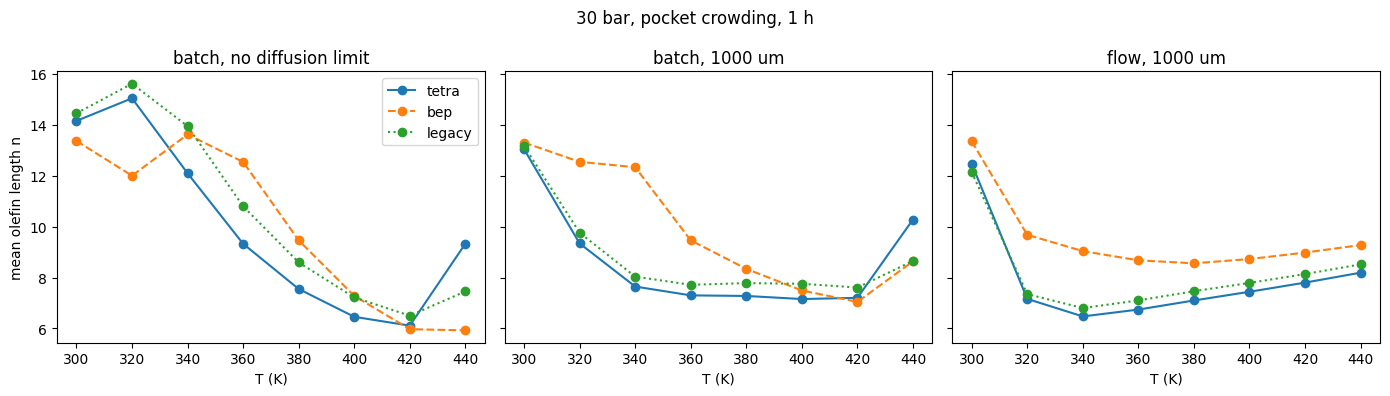

In [3]:
styles = {'tetra': ('C0', '-'), 'bep': ('C1', '--'), 'legacy': ('C2', ':')}
fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (case, g) in zip(axs, res.groupby('case', sort=False)):
    for name, h in g.groupby('variant', sort=False):
        ax.plot(h['T'], h['mean_n'], color=styles[name][0], ls=styles[name][1], marker='o', label=name)
    ax.set_title(case); ax.set_xlabel('T (K)')
axs[0].set_ylabel('mean olefin length n'); axs[0].legend()
fig.suptitle(f'{P} bar, pocket crowding, 1 h')
plt.tight_layout()